# Ensemble learning on Sri Lankan flood risk data

Compare bagging (Random Forest), boosting (XGBoost, LightGBM, CatBoost), and a hybrid stacking model (RF + XGBoost + LightGBM + ANN). The included data is synthetic; results are for coursework demonstration only.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'backend').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data' / 'sri_lanka_flood_risk_dataset_25000.csv'
df = pd.read_csv(DATA)
print('Shape:', df.shape)
display(df.head())

Shape: (25000, 32)


,record_id,district,place_name,latitude,longitude,elevation_m,distance_to_river_m,landcover,soil_type,water_supply,...,infrastructure_score,nearest_hospital_km,nearest_evac_km,flood_risk_score,flood_occurrence_current_event,inundation_area_sqm,is_good_to_live,reason_not_good_to_live,is_synthetic,generation_date
0,F100000,Kegalle,Kudagama,7.416887,81.789107,88,339.2,Wetland,Loamy,Municipal,...,12,2.76,2.74,39.56,No,0,No,Poor infrastructure,True,2025-06-02
1,F100001,Matara,Kiriwatta,6.266956,81.041369,58,1257.6,Agriculture,Clay,Municipal,...,46,1.61,8.45,30.64,No,0,Yes,NaN,True,2024-11-14
2,F100002,Trincomalee,Uduthota East,6.742164,80.927326,80,5225.3,Forest,Silty,Well,...,30,4.40,3.01,35.60,No,0,Yes,NaN,True,2024-03-01
3,F100003,Puttalam,Mahagama East,5.922365,81.484788,111,2950.4,Urban,Sandy,Surface water,...,58,11.44,4.94,17.44,No,0,Yes,NaN,True,2024-11-06
4,F100004,Matara,Welimulla East,7.899872,80.826149,26,228.3,Agriculture,Silty,Well,...,45,17.85,4.65,61.92,No,0,No,High flood risk,True,2024-07-21


,dtype
record_id,str
district,str
place_name,str
latitude,float64
longitude,float64
elevation_m,int64
distance_to_river_m,float64
landcover,str
soil_type,str
water_supply,str


,missing
reason_not_good_to_live,18172
electricity,789
place_name,0
record_id,0
longitude,0
elevation_m,0
distance_to_river_m,0
district,0
landcover,0
soil_type,0


count    25000.000000
mean        33.265946
std         14.783238
min          0.000000
25%         22.547500
50%         32.300000
75%         42.940000
max        100.000000
Name: flood_risk_score, dtype: float64

is_synthetic
True    25000
Name: count, dtype: int64

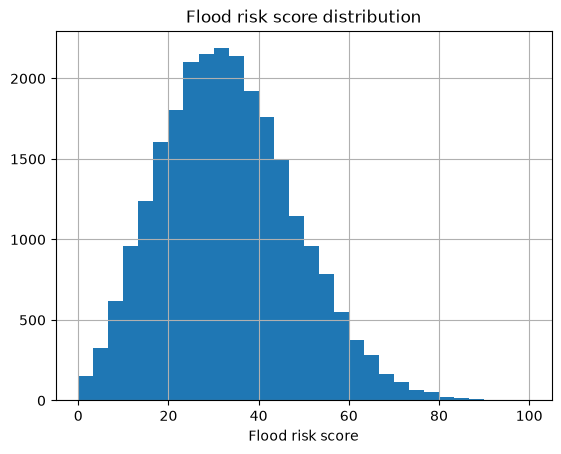

In [2]:
# Review missing values, target distribution, and synthetic-data flag.
display(df.dtypes.to_frame('dtype'))
display(df.isna().sum().sort_values(ascending=False).head(12).to_frame('missing'))
display(df['flood_risk_score'].describe())
if 'is_synthetic' in df:
    display(df['is_synthetic'].value_counts(dropna=False))
df['flood_risk_score'].hist(bins=30)
plt.title('Flood risk score distribution')
plt.xlabel('Flood risk score')
plt.show()

## Leakage review
The flood occurrence, inundation area, and generated post-outcome judgement fields are excluded in `backend/preprocessing.py`. Check every predictor against the intended prediction time before relying on results.

In [3]:
from backend.train_models import train
comparison = train(DATA, target='flood_risk_score', test_size=0.2, seed=42)
display(comparison)

                          Model       R2      MSE     RMSE
            CatBoost (Boosting) 0.998681 0.280714 0.529825
RF + XGB + LightGBM + ANN Stack 0.998030 0.419267 0.647509
            LightGBM (Boosting) 0.997415 0.550193 0.741750
             XGBoost (Boosting) 0.997259 0.583524 0.763888
        Random Forest (Bagging) 0.978931 4.484568 2.117680


,Model,R2,MSE,RMSE
3,CatBoost (Boosting),0.998681,0.280714,0.529825
4,RF + XGB + LightGBM + ANN Stack,0.998030,0.419267,0.647509
2,LightGBM (Boosting),0.997415,0.550193,0.741750
1,XGBoost (Boosting),0.997259,0.583524,0.763888
0,Random Forest (Bagging),0.978931,4.484568,2.117680


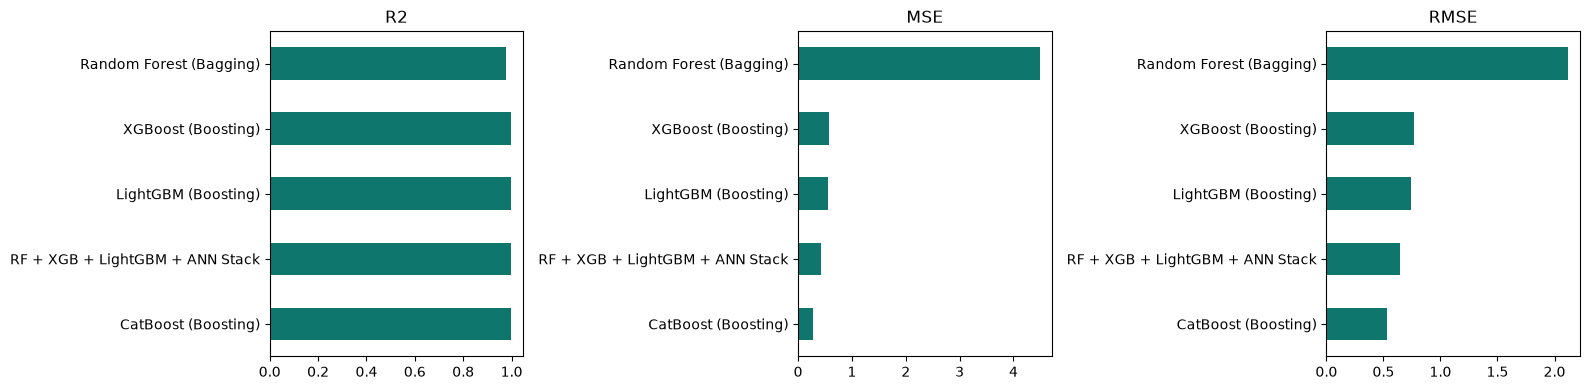

In [4]:
# Compare metrics; R2 higher is better, MSE/RMSE lower are better.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['R2', 'MSE', 'RMSE']):
    comparison.sort_values(metric, ascending=(metric != 'R2')).plot.barh(
        x='Model', y=metric, ax=ax, legend=False, color='#0f766e')
    ax.set_title(metric)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

## Interpretation
1. Does the best model by R² also have the lowest MSE and RMSE?
2. Does stacking improve on the best individual model enough to justify its extra cost?
3. Which features have plausible predictive signal, and could any be leakage or proxies?
4. What changes would be needed for a location-grouped or time-based validation split?

Open the dashboard with `streamlit run dashboard/dashboard.py`. Training writes the same comparison and model bundle used by the UI.

The project implementation was done by the support of Gen AI tools and all tests data validations and program runs done by the author(myself)